In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("T_ONTIME_REPORTING.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   YEAR               539747 non-null  int64  
 1   MONTH              539747 non-null  int64  
 2   DAY_OF_MONTH       539747 non-null  int64  
 3   DAY_OF_WEEK        539747 non-null  int64  
 4   FL_DATE            539747 non-null  str    
 5   OP_UNIQUE_CARRIER  539747 non-null  str    
 6   ORIGIN             539747 non-null  str    
 7   DEST               539747 non-null  str    
 8   CRS_DEP_TIME       539747 non-null  int64  
 9   CRS_ARR_TIME       539747 non-null  int64  
 10  ARR_DEL15          522269 non-null  float64
 11  CANCELLED          539747 non-null  float64
 12  DIVERTED           539747 non-null  float64
 13  CRS_ELAPSED_TIME   539747 non-null  float64
 14  DISTANCE           539747 non-null  float64
dtypes: float64(5), int64(6), str(4)
memory usage: 76.5 MB


In [4]:
df.shape
#15 * 539747 = 8,096,205 data points

(539747, 15)

In [5]:
df.columns.tolist()

['YEAR',
 'MONTH',
 'DAY_OF_MONTH',
 'DAY_OF_WEEK',
 'FL_DATE',
 'OP_UNIQUE_CARRIER',
 'ORIGIN',
 'DEST',
 'CRS_DEP_TIME',
 'CRS_ARR_TIME',
 'ARR_DEL15',
 'CANCELLED',
 'DIVERTED',
 'CRS_ELAPSED_TIME',
 'DISTANCE']

In [6]:
definitions = {
    "YEAR": "Year of the flight",
    "MONTH": "Month of the flight (1-12)",
    "DAY_OF_MONTH": "Day of the month",
    "DAY_OF_WEEK": "Day of the week as a number (1-7)",
    "FL_DATE": "Flight date",
    "OP_UNIQUE_CARRIER": "Airline code. Unique carrier code for the reporting airline",
    "ORIGIN": "Origin airport code (three letters)",
    "DEST": "Destination airport code (three letters)",
    "CRS_DEP_TIME": "Scheduled departure time, local time, written as hhmm (1435 means 2:35 PM)",
    "CRS_ARR_TIME": "Scheduled arrival time, local time, written as hhmm",
    "ARR_DEL15": "Outcome. 1 if the flight arrived 15 or more minutes late, 0 if not",
    "CANCELLED": "1 if the flight was cancelled, 0 if not",
    "DIVERTED": "1 if the flight was diverted to another airport, 0 if not",
    "CRS_ELAPSED_TIME": "Scheduled flight time in minutes, gate to gate",
    "DISTANCE": "Distance between the two airports in miles",
}

In [7]:
df_fl = pd.to_datetime(df["FL_DATE"])
print(df_fl.min(), "to", df_fl.max()) #time period
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"]) #Change the actual FL_DATE column to be in to_datetime format

2025-01-01 00:00:00 to 2025-01-31 00:00:00


In [8]:
print("Carriers:", df["OP_UNIQUE_CARRIER"].nunique())
print("Origin airports:", df["ORIGIN"].nunique()) # of origin airports
print("Destination airports:", df["DEST"].nunique()) # of destination airports
print("Unique routes:", df.groupby(["ORIGIN", "DEST"]).ngroups)
print("Cancelled flights:", int(df["CANCELLED"].sum()))
print("Diverted flights:", int(df["DIVERTED"].sum()))

Carriers: 14
Origin airports: 329
Destination airports: 329
Unique routes: 5649
Cancelled flights: 16312
Diverted flights: 1166


In [9]:
#Missing values 
print(df.isna().sum())

YEAR                     0
MONTH                    0
DAY_OF_MONTH             0
DAY_OF_WEEK              0
FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            17478
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64


In [10]:
print("Cancelled flights with missing ARR_DEL15:",
      df.loc[df["CANCELLED"] == 1, "ARR_DEL15"].isna().mean())
print("Diverted flights with missing ARR_DEL15:",
      df.loc[df["DIVERTED"] == 1, "ARR_DEL15"].isna().mean())
print("Normal flights with missing ARR_DEL15:",
      df.loc[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0), "ARR_DEL15"].isna().sum())

Cancelled flights with missing ARR_DEL15: 1.0
Diverted flights with missing ARR_DEL15: 1.0
Normal flights with missing ARR_DEL15: 0


In [11]:
# Variable types
print(df.dtypes)

YEAR                          int64
MONTH                         int64
DAY_OF_MONTH                  int64
DAY_OF_WEEK                   int64
FL_DATE              datetime64[us]
OP_UNIQUE_CARRIER               str
ORIGIN                          str
DEST                            str
CRS_DEP_TIME                  int64
CRS_ARR_TIME                  int64
ARR_DEL15                   float64
CANCELLED                   float64
DIVERTED                    float64
CRS_ELAPSED_TIME            float64
DISTANCE                    float64
dtype: object


In [12]:
# of duplicated rows.
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 1


In [13]:
df[df.duplicated(keep=False)]

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
531112,2025,1,31,5,2025-01-31,OH,ICT,DCA,1718,2103,NaN,1.0,0.0,165.0,1110.0
531113,2025,1,31,5,2025-01-31,OH,ICT,DCA,1718,2103,NaN,1.0,0.0,165.0,1110.0


In [14]:
print(df[df.duplicated(keep=False)].index.tolist())

[531112, 531113]


In [15]:
#implausible values check
print("CRS_ELAPSED_TIME <= 0:", (df["CRS_ELAPSED_TIME"] <= 0).sum()) #cant have any time less than 0
print("DISTANCE <= 0:", (df["DISTANCE"] <= 0).sum())  #cant have any distances less than 0
print("CRS_DEP_TIME above 2400:", (df["CRS_DEP_TIME"] > 2400).sum()) #cant have any time less than 0
print("CRS_DEP_TIME equal to 2400:", (df["CRS_DEP_TIME"] == 2400).sum()) #cant have any time less than 0

CRS_ELAPSED_TIME <= 0: 0
DISTANCE <= 0: 0
CRS_DEP_TIME above 2400: 0
CRS_DEP_TIME equal to 2400: 0


In [16]:
#CLEANINGS

In [17]:
clean = df[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)].copy()
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"])
clean["FL_DATE"] = pd.to_datetime(clean["FL_DATE"])
clean["DEP_HOUR"] = (clean["CRS_DEP_TIME"] // 100) % 24 #VERY important for model training. Hour of day (DEP_HOUR) gives us the time of day that correlates with other features in the dataset. This is visualized in Figure 2 (a visual, and one compact chart)

print("Rows before:", len(df), "Rows after:", len(clean))
print("Rows removed:", len(df) - len(clean))

Rows before: 539747 Rows after: 522269
Rows removed: 17478


In [18]:
print(clean.isna().sum())

YEAR                 0
MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
FL_DATE              0
OP_UNIQUE_CARRIER    0
ORIGIN               0
DEST                 0
CRS_DEP_TIME         0
CRS_ARR_TIME         0
ARR_DEL15            0
CANCELLED            0
DIVERTED             0
CRS_ELAPSED_TIME     0
DISTANCE             0
DEP_HOUR             0
dtype: int64


In [19]:
print(clean.duplicated().sum())
#End of Cleanings

0


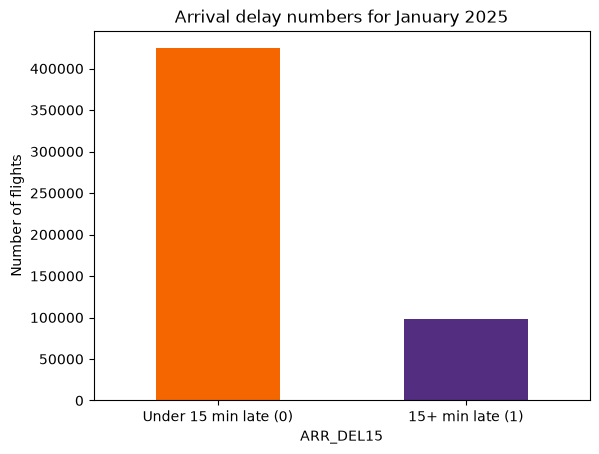

Delay rate: 0.1879


In [20]:
#FIGURE 1
counts = clean["ARR_DEL15"].value_counts().sort_index()
ax = counts.plot(kind="bar", color=["#F56600", "#522D80"])
ax.set_xticklabels(["Under 15 min late (0)", "15+ min late (1)"], rotation=0)
ax.set_ylabel("Number of flights")
ax.set_title("Arrival delay numbers for January 2025")

plt.savefig("fig1_outcome.png", dpi=600, bbox_inches="tight")
plt.show()

print("Delay rate:", clean["ARR_DEL15"].mean().round(4))

In [21]:
#Compact Tables 1 & 2
table1 = pd.DataFrame({
    "Measure": ["Rows (raw)", "Rows (clean)", "Cancelled removed", "Diverted removed", "Columns", "Unique Carriers",
                "Origin airports", "Missing values, clean data"],
    "Value": [len(df), len(clean), int(df["CANCELLED"].sum()),
              int(df["DIVERTED"].sum()), df.shape[1],
              clean["OP_UNIQUE_CARRIER"].nunique(),
              clean["ORIGIN"].nunique(), int(clean.isna().sum().sum())]
})
display(table1)

,Measure,Value
0,Rows (raw),539747
1,Rows (clean),522269
2,Cancelled removed,16312
3,Diverted removed,1166
4,Columns,15
5,Unique Carriers,14
6,Origin airports,329
7,"Missing values, clean data",0


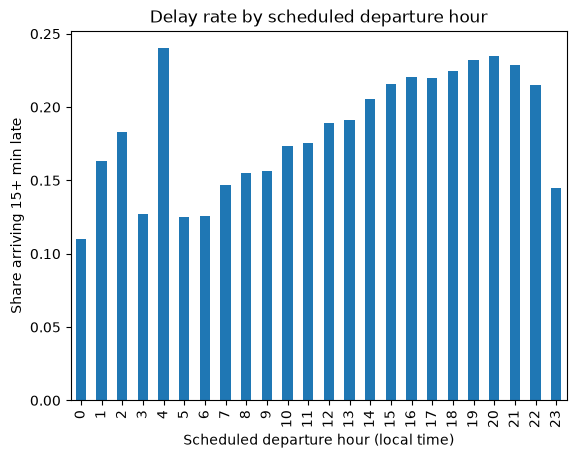

,flights,delay_rate
DEP_HOUR,,
0,564,0.110
1,282,0.163
2,93,0.183
3,55,0.127
4,25,0.240
5,13411,0.125
6,35230,0.126
7,36580,0.147
8,37650,0.155


In [22]:
#Figure two
rate_hour = clean.groupby("DEP_HOUR")["ARR_DEL15"].mean()
ax = rate_hour.plot(kind="bar")
ax.set_xlabel("Scheduled departure hour (local time)")
ax.set_ylabel("Share arriving 15+ min late")
ax.set_title("Delay rate by scheduled departure hour")
plt.savefig("fig2_hour.png", dpi=500, bbox_inches="tight")
plt.show()

hour_summary = clean.groupby("DEP_HOUR")["ARR_DEL15"].agg(flights="count", delay_rate="mean").round(3)
display(hour_summary)

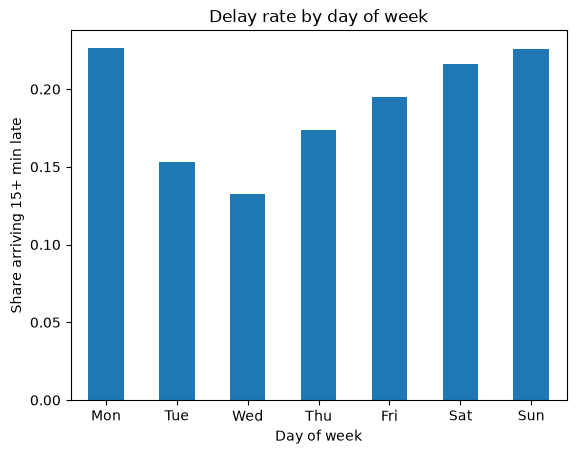

In [23]:
#Figure 3
rate_dow = clean.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean()
ax = rate_dow.plot(kind="bar")
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ax.set_xlabel("Day of week")
ax.set_ylabel("Share arriving 15+ min late")
ax.set_title("Delay rate by day of week")
plt.savefig("fig3_dow.png", dpi=500, bbox_inches="tight")
plt.show()

In [24]:
print(pd.crosstab(df["FL_DATE"].dt.day_name(), df["DAY_OF_WEEK"]))
display(clean.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean().round(3))

DAY_OF_WEEK      1      2      3      4      5      6      7
FL_DATE                                                     
Friday           0      0      0      0  91861      0      0
Monday       73166      0      0      0      0      0      0
Saturday         0      0      0      0      0  63251      0
Sunday           0      0      0      0      0      0  73583
Thursday         0      0      0  92617      0      0      0
Tuesday          0  63686      0      0      0      0      0
Wednesday        0      0  81583      0      0      0      0


DAY_OF_WEEK
1    0.226
2    0.153
3    0.133
4    0.174
5    0.195
6    0.216
7    0.226
Name: ARR_DEL15, dtype: float64

In [25]:
##split preview
cut = pd.Timestamp("2025-01-22")
train = clean[clean["FL_DATE"] < cut]
test = clean[clean["FL_DATE"] >= cut]
print("Train rows:", len(train), "Test rows:", len(test))
print("Train delay rate:", train["ARR_DEL15"].mean())
print("Test delay rate:", test["ARR_DEL15"].mean())

Train rows: 353164 Test rows: 169105
Train delay rate: 0.21327768402215402
Test delay rate: 0.13487478194021466
